In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
import time
import os

from pygments.style import ansicolors

device = (
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print(f"Device: {device}")

if device == "mps":
    print("GPU: Apple Silicon GPU")

Device: mps
GPU: Apple Silicon GPU


In [2]:
DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

if not os.path.exists("shakespeare.txt"):
    import urllib.request
    urllib.request.urlretrieve(DATA_URL , "shakespeare.txt")

with open("shakespeare.txt" , "r") as file :
    text = file.read()

print(f"Total characters: {len(text):,}")
print(f"First 200 characters:\n{text[:200]}")

Total characters: 1,115,394
First 200 characters:
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


## Character Level Tokenization

In [3]:
## build character vocabulary

chars = sorted(set(text))
vocab_size = len(chars)

char_to_idx = {c : i for i , c in enumerate(chars)}
idx_to_char = {i : c for i , c in enumerate(chars)}

def encode(s) :
    return [char_to_idx[c] for c in s]

def decode(ids) :
    return "".join([idx_to_char[i] for i in ids])

print(f"Vocabulary size : {vocab_size}")
print(f"Characters : {"".join(chars)}")
print("Example encoding")
print(f"Hello -> {encode("Hello")}")
print(f"  {encode('Hello')} -> '{decode(encode('Hello'))}'")

Vocabulary size : 65
Characters : 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
Example encoding
Hello -> [20, 43, 50, 50, 53]
  [20, 43, 50, 50, 53] -> 'Hello'


In [4]:
# train test split(90 / 10)

data = torch.tensor(encode(text) , dtype=torch.long)

n = int(0.9 * len(data))
train_data = data[:n]
test_data = data[n:]

print(f"Training Token : {len(train_data)}")
print(f"Test Token : {len(test_data)}")

Training Token : 1003854
Test Token : 111540


In [44]:
def get_batch(split , batch_size , context_length) :
    d = train_data if split == "train" else test_data
    ix = torch.randint(len(d) - context_length , (batch_size,))
    x = torch.stack([d[i : i + context_length] for i in ix])
    y = torch.stack([d[i + 1 : i + context_length + 1] for i in ix])
    return x.to(device) , y.to(device)

xb, yb = get_batch("train", batch_size=4, context_length=8)
print(f"Input shape:  {xb.shape}  (batch_size x context_length)")
print(f"Target shape: {yb.shape}")
print(f"\nExample (first sequence):")
print(f"  Input:  {decode(xb[0].tolist())!r}")
print(f"  Target: {decode(yb[0].tolist())!r}")
print(f"  (Target is input shifted by 1 character)")

Input shape:  torch.Size([4, 8])  (batch_size x context_length)
Target shape: torch.Size([4, 8])

Example (first sequence):
  Input:  ', quick,'
  Target: ' quick, '
  (Target is input shifted by 1 character)


Section 1: RMSNorm
What you know: LayerNorm subtracts mean, divides by std, then scales and shifts.

The upgrade: RMSNorm skips the mean subtraction and the shift. Just divide by the root-mean-square, then scale. Simpler, faster, works just as well.




In [45]:
class RMSNorm(nn.Module):
    def __init__(self , dim , eps = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self , x):
        rms = torch.sqrt(x.pow(2).mean(dim =-1 , keepdim=True) + self.eps)
        return (x / rms) * self.weight

DROPOUT = 0.2

demo_x = torch.randn(2  , 4 , 8)
norm = RMSNorm(8)
demo_out = norm(demo_x)

print("RMSNorm demo")
print(f"  Input  - mean: {demo_x.mean():.3f}, std: {demo_x.std():.3f}")
print(f"  Output - mean: {demo_out.mean():.3f}, std: {demo_out.std():.3f}")
print(f"  Input range:  [{demo_x.min():.3f}, {demo_x.max():.3f}]")
print(f"  Output range: [{demo_out.min():.3f}, {demo_out.max():.3f}]")
print(f"\n  Parameters: just a scale vector of size {norm.weight.shape}")

RMSNorm demo
  Input  - mean: 0.164, std: 1.016
  Output - mean: 0.124, std: 1.000
  Input range:  [-2.051, 2.899]
  Output range: [-1.934, 2.168]

  Parameters: just a scale vector of size torch.Size([8])


---
# Section 2: Rotary Positional Embeddings (RoPE)

**What you know:** Sinusoidal positional encoding — add a fixed pattern to embeddings.

**The upgrade:** RoPE *rotates* Q and K vectors based on position. The dot product then naturally captures *relative* distance between tokens.

Like a clock: the angle between 3 o'clock and 5 o'clock = the angle between 7 o'clock and 9 o'clock. Absolute position doesn't matter, only the gap.

In [46]:
def precompute_freq(head_dim , max_seq_len , base=10000.0):
    """
    Precompute cosine and sine tables for RoPE.

    Each pair of dimensions gets a different rotation frequency.
    Low dims  -> fast rotation -> short-range patterns
    High dims -> slow rotation -> long-range patterns
    """
    freq = 1.0 / (base ** (torch.arange(0 , head_dim , 2).float() / head_dim))
    position = torch.arange(max_seq_len).float()
    angles = torch.outer(position , freq)
    return torch.cos(angles) , torch.sin(angles)

def apply_rope(x , cos , sin) :
    """
)    Apply rotary embeddings to a tensor.

    x: [batch, n_heads, seq_len, head_dim]s
    cos, sin: [seq_len, head_dim // 2]

    For each pair of dimensions (2i, 2i+1):
    rotated_2i   = x_2i * cos - x_2i+1 * sin
    rotated_2i+1 = x_2i * sin + x_2i+1 * cos
    """

    seq_len = x.shape[2]
    cos = cos[:seq_len].unsqueeze(0).unsqueeze(0)
    sin = sin[:seq_len].unsqueeze(0).unsqueeze(0)

    x1 = x[... , ::2]
    x2 = x[... , 1::2]

    out1 = x1 * cos - x2 * sin
    out2 = x1 * sin + x2 * cos

    return torch.stack([out1 , out2] , dim=-1).flatten(-2)

In [47]:
def repeat_kv(x, n_rep):
    if n_rep == 1:
        return x

    b, n_kv, seq, hd = x.shape

    return (
        x[:, :, None, :, :]
        .expand(b, n_kv, n_rep, seq, hd)
        .reshape(b, n_kv * n_rep, seq, hd)
    )

In [48]:
class GroupQueryAttention(nn.Module) :
    def __init__(self , d_module , n_heads , n_kv_heads):
        super().__init__()
        assert d_module % n_heads == 0
        assert n_heads % n_kv_heads == 0

        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads
        self.n_rep = n_heads // n_kv_heads
        self.head_dim = d_module // n_heads

        self.q_proj = nn.Linear(d_module , n_heads * self.head_dim , bias=False)
        self.k_proj = nn.Linear(d_module , n_kv_heads * self.head_dim , bias=False)
        self.v_proj = nn.Linear(d_module , n_kv_heads * self.head_dim , bias=False)
        self.o_proj = nn.Linear(n_heads *self.head_dim , d_module , bias=True)

    def forward(self, x, rope_cos, rope_sin):
        b, seq, _ = x.shape

        # Project Q, K, V
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        # Reshape into heads
        q = q.view(b, seq, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(b, seq, self.n_kv_heads, self.head_dim).transpose(1, 2)
        v = v.view(b, seq, self.n_kv_heads, self.head_dim).transpose(1, 2)

        # Apply RoPE to Q and K (not V!)
        q = apply_rope(q, rope_cos, rope_sin)
        k = apply_rope(k, rope_cos, rope_sin)

        # Repeat KV heads to match Q heads
        k = repeat_kv(k, self.n_rep)
        v = repeat_kv(v, self.n_rep)

        # print("q shape:", q.shape)
        # print("k shape:", k.shape)
        # print("v shape:", v.shape)
        # print("n_heads:", self.n_heads)
        # print("n_kv_heads:", self.n_kv_heads)
        # print("n_rep:", self.n_rep)

        # Scaled dot-product attention with causal mask
        scale = 1.0 / math.sqrt(self.head_dim)
        scores = (q @ k.transpose(-2, -1)) * scale

        mask = torch.triu(torch.ones(seq, seq, device=x.device), diagonal=1).bool()
        scores = scores.masked_fill(mask, float("-inf"))

        weights = F.softmax(scores, dim=-1)

        # Dropout on attention weights (regularization)
        weights = F.dropout(weights, p=DROPOUT, training=self.training)

        out = weights @ v

        # Merge heads and project
        out = out.transpose(1, 2).contiguous().view(b, seq, -1)
        return self.o_proj(out)


In [49]:
class SwiGLU(nn.Module) :
    def __init__(self , d_model , hidden_dim):
        super().__init__()
        self.w_gate = nn.Linear(d_model , hidden_dim , bias=False)
        self.w_up = nn.Linear(d_model , hidden_dim , bias=False)
        self.w_down = nn.Linear(hidden_dim , d_model , bias=False)

    def forward(self , x):
        gate = F.silu(self.w_gate(x))
        up = self.w_up(x)
        return F.dropout(self.w_down(gate * up) , p=DROPOUT , training=self.training)

In [50]:
class TransformerBlock(nn.Module) :
    def __init__(self , d_model , n_heads , n_kv_heads , ffn_hidden_dim):
        super().__init__()
        self.attn_norm = RMSNorm(d_model)
        self.attention = GroupQueryAttention(d_model , n_heads , n_kv_heads)
        self.ffn_norms = RMSNorm(d_model)
        self.ffn = SwiGLU(d_model , ffn_hidden_dim)

    def forward(self , x , rope_cos , rope_sin):
        # pre-norm -> Attention -> Residual
        x = x + self.attention(self.attn_norm(x) , rope_cos , rope_sin)
        ## pre-norm -> FFN -> Residual
        x = x + self.ffn(self.ffn_norms(x))
        return x


In [51]:
class MiniLLM(nn.Module) :
    def __init__(self , vocab_sizes , d_model , n_layers , n_heads , n_kv_heads , ffn_hidden_dim , max_seq_len):
        super().__init__()

        self.d_model = d_model
        self.max_seq_len = max_seq_len

        self.token_embedding = nn.Embedding(vocab_sizes , d_model)

        self.layers = nn.ModuleList([
            TransformerBlock(d_model , n_heads , n_kv_heads , ffn_hidden_dim)
            for _ in range(n_layers)
        ])

        self.lm_head = nn.Linear(d_model, vocab_sizes, bias=False)

        self.final_norm = RMSNorm(d_model)
        self.lm_head.weight = self.token_embedding.weight

        head_dim = d_model // n_heads
        rope_cos , rope_sin = precompute_freq(head_dim , max_seq_len)
        self.register_buffer("rope_cos" , rope_cos)
        self.register_buffer("rope_sin" , rope_sin)

        self.apply(self._init_weights)

    def _init_weights(self , module):
        if isinstance(module , nn.Linear) :
            nn.init.normal_(module.weight , mean=0.0 , std=0.2)
        elif isinstance(module , nn.Embedding):
            nn.init.normal_(module.weight , mean=0.0 , std=0.2)

    def forward(self , idx , targets = None):
        b , seq_len = idx.size()

        x = self.token_embedding(idx)

        for layer in self.layers:
            x = layer(x , self.rope_cos , self.rope_sin)

        x = self.final_norm(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.view(-1 , logits.size(-1)),
                targets.view(-1)
            )

        return logits , loss

In [52]:
config = {
    "vocab_sizes" : vocab_size ,
    "d_model" : 256  ,
    "n_layers" : 4 ,
    "n_heads" : 8 ,
    "n_kv_heads" : 2 ,
    "ffn_hidden_dim" : 680 ,
    "max_seq_len" : 256
}

model = MiniLLM(**config).to(device)


total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("=" * 50)
print("  MODEL SUMMARY")
print("=" * 50)
print(f"  Vocabulary:      {config['vocab_sizes']}")
print(f"  Embedding dim:   {config['d_model']}")
print(f"  Layers:          {config['n_layers']}")
print(f"  Query heads:     {config['n_heads']}")
print(f"  KV heads:        {config['n_kv_heads']} (GQA ratio: {config['n_heads']//config['n_kv_heads']}:1)")
print(f"  FFN hidden dim:  {config['ffn_hidden_dim']}")
print(f"  Context length:  {config['max_seq_len']}")
print(f"  Head dim:        {config['d_model'] // config['n_heads']}")
print(f"{'=' * 50}")
print(f"  Total parameters:     {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Model size (approx):  {total_params * 4 / 1e6:.1f} MB (float32)")
print(f"{'=' * 50}")

  MODEL SUMMARY
  Vocabulary:      65
  Embedding dim:   256
  Layers:          4
  Query heads:     8
  KV heads:        2 (GQA ratio: 4:1)
  FFN hidden dim:  680
  Context length:  256
  Head dim:        32
  Total parameters:     2,764,288
  Trainable parameters: 2,764,288
  Model size (approx):  11.1 MB (float32)


In [53]:
BATCH_SIZE = 64
CONTEXT_LEN = config["max_seq_len"]
LEARNING_RATE = 3e-4
MAX_STEPS = 3000
EVAL_INTERVAL = 250
EVAL_STEPS = 20
LOG_INTERVAL = 50

optimizer = torch.optim.Adam(model.parameters() , lr = LEARNING_RATE)

In [54]:
@torch.no_grad()
def estimate_loss() :
    model.eval()
    out = {}
    for split in ["train" , "test"]:
        losses = []
        for _ in range(EVAL_STEPS):
            xb , yb = get_batch(split , BATCH_SIZE , context_length=CONTEXT_LEN)
            _, loss = model(xb , yb)
            losses.append(loss.item())
        out[split] = sum(losses) / len(losses)
    model.train()
    return out

In [57]:
# --- Training Loop ---
print("Starting training...")
print(f"  {MAX_STEPS} steps, batch_size={BATCH_SIZE}, context_len={CONTEXT_LEN}")
print(f"  Evaluating every {EVAL_INTERVAL} steps")
print("-" * 60)

train_losses = []
val_losses = []
step_log = []
start_time = time.time()

model.train()
for step in range(MAX_STEPS):
    xb, yb = get_batch("train", BATCH_SIZE, CONTEXT_LEN)

    logits, loss = model(xb, yb)

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

    if step % LOG_INTERVAL == 0:
        elapsed = time.time() - start_time
        print(f"  Step {step:5d}/{MAX_STEPS} | Loss: {loss.item():.4f} | Time: {elapsed:.0f}s")

    if step % EVAL_INTERVAL == 0 or step == MAX_STEPS - 1:
        losses = estimate_loss()
        train_losses.append(losses["train"])
        val_losses.append(losses["test"])
        step_log.append(step)
        if step > 0:
            elapsed = time.time() - start_time
            steps_per_sec = step / elapsed
            remaining = (MAX_STEPS - step) / steps_per_sec
            print(f"  >>> Eval @ step {step}: train={losses['train']:.4f}, val={losses['test']:.4f} | ~{remaining:.0f}s remaining")

total_time = time.time() - start_time
print("-" * 60)
print(f"Training complete! Total time: {total_time:.0f}s ({total_time/60:.1f} min)")
print(f"Final train loss: {train_losses[-1]:.4f}")
print(f"Final val loss:   {val_losses[-1]:.4f}")

Starting training...
  3000 steps, batch_size=64, context_len=256
  Evaluating every 250 steps
------------------------------------------------------------
  Step     0/3000 | Loss: 7.9843 | Time: 0s
  Step    50/3000 | Loss: 3.5488 | Time: 86s
  Step   100/3000 | Loss: 2.9998 | Time: 138s
  Step   150/3000 | Loss: 2.8341 | Time: 189s
  Step   200/3000 | Loss: 2.7002 | Time: 257s
  Step   250/3000 | Loss: 2.6499 | Time: 326s
  >>> Eval @ step 250: train=2.5316, val=2.5613 | ~3757s remaining
  Step   300/3000 | Loss: 2.5872 | Time: 414s
  Step   350/3000 | Loss: 2.5654 | Time: 496s
  Step   400/3000 | Loss: 2.5144 | Time: 579s
  Step   450/3000 | Loss: 2.4642 | Time: 662s
  Step   500/3000 | Loss: 2.4467 | Time: 743s
  >>> Eval @ step 500: train=2.3426, val=2.3638 | ~3805s remaining
  Step   550/3000 | Loss: 2.4227 | Time: 840s
  Step   600/3000 | Loss: 2.3894 | Time: 917s
  Step   650/3000 | Loss: 2.3473 | Time: 987s
  Step   700/3000 | Loss: 2.3246 | Time: 1060s
  Step   750/3000 | Lo

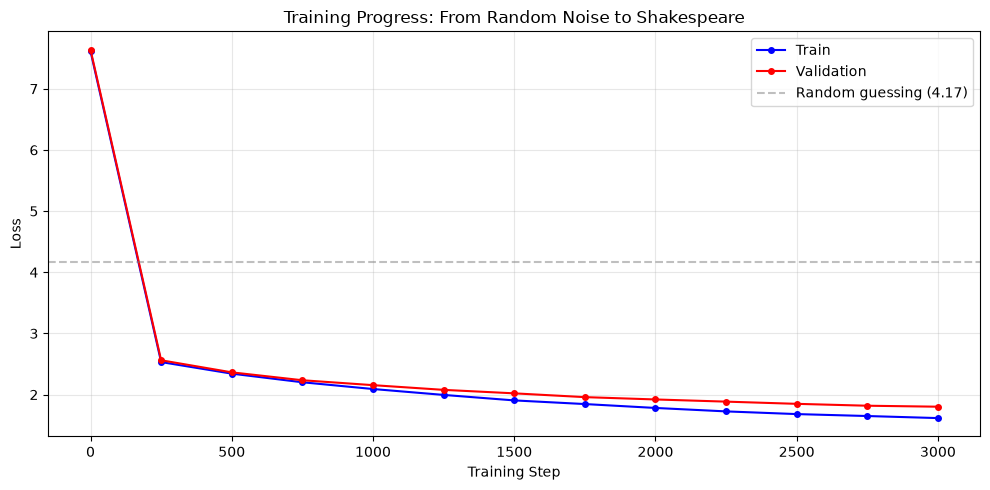

In [58]:
# --- Plot Loss Curve ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(step_log, train_losses, "b-o", label="Train", markersize=4)
ax.plot(step_log, val_losses, "r-o", label="Validation", markersize=4)
ax.axhline(y=math.log(vocab_size), color="gray", linestyle="--", alpha=0.5,
           label=f"Random guessing ({math.log(vocab_size):.2f})")
ax.set_xlabel("Training Step")
ax.set_ylabel("Loss")
ax.set_title("Training Progress: From Random Noise to Shakespeare")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [59]:
@torch.no_grad()
def generate(model, prompt, max_new_tokens=500, temperature=0.8):
    """
    Generate text autoregressively.

    temperature controls randomness:
      low (0.3)  -> conservative, repetitive
      mid (0.8)  -> balanced
      high (1.2) -> creative, chaotic
    """
    model.eval()
    tokens = encode(prompt)
    tokens = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)

    for _ in range(max_new_tokens):
        context = tokens[:, -config["max_seq_len"]:]
        logits, _ = model(context)
        logits = logits[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)
        tokens = torch.cat([tokens, next_token], dim=1)

    return decode(tokens[0].tolist())

In [60]:
# --- Generate at different temperatures ---
prompt = "ROMEO:"

print("=" * 60)
print(f"  PROMPT: {prompt!r}")
print("=" * 60)

for temp in [0.5, 0.8, 1.0, 1.2]:
    print(f"\n{'_' * 60}")
    print(f"  Temperature = {temp}")
    print(f"{'_' * 60}")
    output = generate(model, prompt, max_new_tokens=300, temperature=temp)
    print(output)

  PROMPT: 'ROMEO:'

____________________________________________________________
  Temperature = 0.5
____________________________________________________________
ROMEO:
And do the was the strace to the come and the shall service,
And so he the come of and and the see with her and and prited
The ship and my stranger such of thou word;
And this like a stated that soul, come his need with the was and and and not the proce.

ROMEO:
And the was the would be the for you

____________________________________________________________
  Temperature = 0.8
____________________________________________________________
ROMEO:
Here good thou with deen his face the dies.

DUKE OF YORK:
Constle consection beother my word.

ROMEO:
That's the well thus fame the leave his loud,
Hark prind dest him three have with that days,
The pans we art look, as the with himself.

DUKE OF AUMERLE:
What we will come, honour aboth be feel
Th

____________________________________________________________
  Temperature = 1.0